# Part-C (Arabic Egypt Customer Reviews Dataset)

## Overview
The **Arabic Egypt Customer Reviews** dataset (`Arabic Egypt Customer Reviews.csv`) is a collection of customer feedback written primarily in **Egyptian Arabic**. This part focuses on dialectal Arabic, particularly sentiment analysis, opinion mining, and customer experience analytics.

---

## Dataset Details
* **Primary Language / Dialect:** Egyptian Arabic, with occasional Modern Standard Arabic and code-switching (Arabizi / English loanwords).
* **Domain:** Customer Reviews & Feedback (for example local services).
* **Total Records:** 40,046 records

---

## Description
The dataset consists of the following columns:

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| `Review_Description` | `String` | The raw text of the customer review in Egyptian Arabic. |
| `Rating` | `String` | Positive, or Negative review from Customers. |
| `Company` | `String` | The rating that came from the company application (for example talabat). |

---

## Key Characteristics of the Dataset
This data presents unique linguistic features that we should consider during preprocessing:
* **Dialectal Vocabulary & Idioms:** Contains everyday Egyptian expressions, slang, and negations (e.g., *مش*, *ما...ش*).
* **Code-Switching & Arabizi:** Includes mixed Arabic-English text and transliterated Arabic words using Latin characters and numbers.
* **Orthographic Variations:** Inconsistent spelling of characters such as *Alef* (`أ`, `إ`, `آ` $\rightarrow$ `ا`), *Ta Marbuta* (`ة` $\rightarrow$ `ه`), and *Ya* (`ي` $\rightarrow$ `ى`).
* **Informal Markers:** Heavy use of emojis, repeated characters for emphasis (elongation/stretching), and lack of diacritics (*Tashkeel*).

---

## Potential Use Cases
* **Sentiment Analysis:** Training binary or multi-class classifiers to detect customer satisfaction in Egyptian dialect.
* **Aspect-Based Sentiment Analysis:** Extracting sentiment toward specific attributes like product quality.
* **Dialect Identification & Translation:** Benchmarking dialectal Arabic models or building Egyptian-to-MSA / Egyptian-to-English translation pipelines.
* **Topic Modeling:** Discovering recurring customer complaints, feature requests, and trending themes.

In [1]:
# Important libraries for this Task.
import pandas as pd # Data Preprocessing
import numpy as np # Array and Numerical Processing
import matplotlib.pyplot as plt # Visualization
import seaborn as sns # Another Visualization (on top of matplotlib)
import re # For regular expression that enables text validation, parsing, and manipulation
from scipy import sparse # Another array and numerical processing (on top of numpy)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, precision_recall_fscore_support)

In [ ]:
df = pd.read_csv('../Dataset/Arabic_Egypt_Customer_Reviews.csv')
print(df.head())
print()
print("shape:", df.shape)
print()
print(df["rating"].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: '/content/Arabic_Egypt_Customer_Reviews.csv'

In [ ]:
# Replace each 'Positive' or 'Negative' with integer values
# 1: Positive, 0: Negative

df = df.dropna(subset=["review_description"]) # Dropping Nulls
df = df[df["rating"].isin(["positive", "negative"])].copy() # Just leave the Neutral one for this model
df["label"] = (df["rating"] == "positive").astype(int)
df = df.drop(['rating'], axis=1)
print(df.head())

                                  review_description company  label
0                                               رائع  talbat      1
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...  talbat      1
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  talbat      0
3                 لماذا لا يمكننا طلب من ماكدونالدز؟  talbat      0
4  البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...  talbat      0


In [ ]:
# Cleaning the data

ARABIC_STOPWORDS = set("""
في من على الى إلى عن مع هذا هذه ذلك تلك هنا هناك هو هي هم هن انا انت انتم نحن
أنا أنت التي الذي الذين اللذان اللتان ما ماذا لماذا متى كيف اين أين اي أي كل بعض
غير بعد قبل حتى اذا إذا لو ان أن إن انه أنه انها أنها كان كانت يكون تكون كانوا
قد لقد ثم او أو و ف ب ل ك لدى لدي عند عندما حيث بين خلال منذ فقط ايضا أيضا
هذا هاذا هاد دي ده دا دى ديه كده كدا ايه إيه ليه ازاي فين امتى مين اللي
علي عليه عليها عليهم منه منها منهم له لها لهم به بها بهم فيه فيها فيهم
يا اما أما إما لكن لكنه لكنها بل ولا ولكن اللى الى الي
""".split()) # Filter out high-frequency, low-meaning words before feeding the data into the Models

# Negation / sentiment-critical words must be KEPT (they are not noise here)
KEEP = {"لا", "لم", "لن", "ليس", "مش", "ما", "غير", "بدون", "مفيش", "ماعندي"}
ARABIC_STOPWORDS -= KEEP

HTML = re.compile(r"<[^>]+>") # Removing HTML tags form a sentence in the Dataset
URL = re.compile(r"http\S+|www\.\S+") # Removes web links
DIACRITICS = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]") # Removing Tashkel and Quranic Words and map it to the same token
NON_TEXT = re.compile(r"[^\w\s]|_", re.UNICODE) # Removing punctuations, emojis, and special symbols
DIGITS = re.compile(r"[0-9\u0660-\u0669\u06F0-\u06F9]+") # latin + arabic-indic digits
REPEAT = re.compile(r"(.)\1{2,}") # Detect repeated Arabic Characters

In [ ]:
# Continuing to clean the data

def clean(text: str) -> str:
    t = str(text).lower() # lowercase
    t = HTML.sub(" ", t) # HTML tags
    t = URL.sub(" ", t)
    t = DIACRITICS.sub("", t).replace("ـ", "") # tashkeel + tatweel
    t = NON_TEXT.sub(" ", t) # punctuation (Arabic + emoji)
    t = DIGITS.sub(" ", t) # numbers
    t = re.sub("[إأآا]", "ا", t) # letter normalisation
    t = t.replace("ى", "ي").replace("ة", "ه")
    t = REPEAT.sub(r"\1", t) # Repeated Arabic Characters(for example رااائع -> رائع)
    toks = [w for w in t.split() if w not in NORM_STOP]
    return " ".join(toks)

def _norm(w):
    w = re.sub("[إأآا]", "ا", w).replace("ى", "ي").replace("ة", "ه")
    return w
NORM_STOP = {_norm(w) for w in ARABIC_STOPWORDS}

In [ ]:
df["clean"] = df["review_description"].map(clean)
df = df[df["clean"].str.len() > 0]
n_before = len(df)
df = df.drop_duplicates(subset="clean").reset_index(drop=True) # avoid train/test leakage

print(f"After cleaning: {n_before} records, after removing duplicate texts: {len(df)}")
print(df["label"].value_counts(normalize=True).round(3).to_dict(), "(1 = satisfied)")

After cleaning: 37187 records, after removing duplicate texts: 33100
{1: 0.596, 0: 0.404} (1 = satisfied)


In [ ]:
print(df.head())

                                  review_description company  label  \
0                                               رائع  talbat      1   
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...  talbat      1   
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  talbat      0   
3                 لماذا لا يمكننا طلب من ماكدونالدز؟  talbat      0   
4  البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...  talbat      0   

                                               clean  
0                                               رائع  
1   برنامج رائع جدا يساعد تلبيه الاحتياجات بشكل اسرع  
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  
3                           لا يمكننا طلب ماكدونالدز  
4  البرنامج بيظهر المطاعم مغلقه بتكون فاتحه بقاله...  


In [ ]:
# Splitting the data after cleaning

X, y = df["clean"].values, df["label"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_test, y_test, test_size=0.50, stratify=y_test, random_state=42)
print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_te)}")

Train 23170 | Val 4965 | Test 4965


In [ ]:
# TF-IDF Feature extraction (fit on train only)
MAX_FEATURES = 20000
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=MAX_FEATURES, min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(X_train)
Xval = vec.transform(X_val)
Xte = vec.transform(X_te)
VOCAB = len(vec.vocabulary_)
print("TF-IDF vocabulary size actually used:", VOCAB)

TF-IDF vocabulary size actually used: 20000



Logistic Regression tuning on validation set:
      C  val_acc  val_macroF1
  0.01   0.6070       0.4053
  0.03   0.7571       0.7095
  0.10   0.8338       0.8183
  0.30   0.8602       0.8510
  1.00   0.8741       0.8671
  3.00   0.8765       0.8702
 10.00   0.8691       0.8628
 30.00   0.8604       0.8538
100.00   0.8520       0.8451 
-> best C = 3.0

Linear SVM tuning on validation set:
      C  val_acc  val_macroF1
  0.01   0.8280       0.8109
  0.03   0.8576       0.8482
  0.10   0.8727       0.8656
  0.30   0.8747       0.8682
  1.00   0.8661       0.8595
  3.00   0.8544       0.8473
 10.00   0.8407       0.8331
 30.00   0.8286       0.8207
100.00   0.8207       0.8124 
-> best C = 0.3


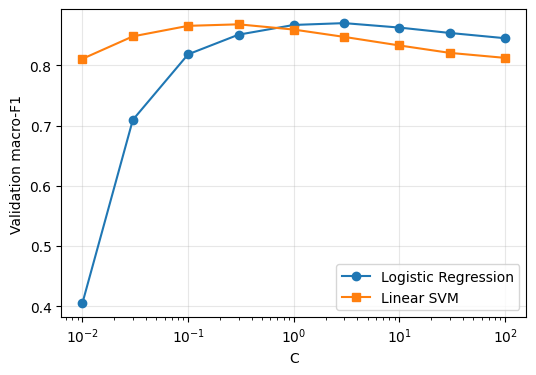

In [ ]:
# hyperparameter tuning (on val set)

def tune(make, grid, name):
    rows = []
    for c in grid:
        m = make(c).fit(Xtr, y_train)
        p = m.predict(Xval)
        rows.append((c, accuracy_score(y_val, p), precision_recall_fscore_support(y_val, p, average="macro")[2]))
    t = pd.DataFrame(rows, columns=["C", "val_acc", "val_macroF1"])
    best = t.sort_values(["val_macroF1", "val_acc"], ascending=False).iloc[0]["C"]
    print(f"\n{name} tuning on validation set:\n", t.round(4).to_string(index=False), f"\n-> best C = {best}")
    return best, t

GRID = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
best_lr_C, t_lr = tune(lambda c: LogisticRegression(C=c, max_iter=2000, random_state=42), GRID, "Logistic Regression") # Logistic Regression
best_svm_C, t_svm = tune(lambda c: LinearSVC(C=c, random_state=42, max_iter=10000), GRID, "Linear SVM") # Linear SVM

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(t_lr["C"], t_lr["val_macroF1"], "o-", label="Logistic Regression")
ax.semilogx(t_svm["C"], t_svm["val_macroF1"], "s-", label="Linear SVM")
ax.set_xlabel("C"); ax.set_ylabel("Validation macro-F1"); ax.legend(); ax.grid(alpha=.3)
# plt.tight_layout(); plt.savefig(OUT + "tuning_curves.png", dpi=150); plt.close()

# Final models: refit on TRAIN only with best C (val used for selection, test untouched)
lr = LogisticRegression(C=best_lr_C, max_iter=2000, random_state=42).fit(Xtr, y_train)
svm = LinearSVC(C=best_svm_C, random_state=42, max_iter=10000).fit(Xtr, y_train)

In [ ]:
import os
import joblib

os.makedirs("saved_models", exist_ok=True)

joblib.dump(vec, "saved_models/tfidf_vectorizer.pkl")

joblib.dump(lr, "saved_models/logistic_regression.pkl")

joblib.dump(svm, "saved_models/linear_svm.pkl")

print("All models saved successfully!")